In [1]:
import itertools
import json
import sys
from pathlib import Path

import networkx as nx
import numpy as np

# Make imports robust whether the notebook runs from project root or notebooks/
project_root = Path.cwd().resolve()
if not (project_root / "src").exists() and (project_root.parent / "src").exists():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.graph_dataset_preparation import ensure_unique_edge_weights
from src.graph_utils import compute_Q, ktte, kttw, plot_weighted_graphs

In [2]:
def load_graphs_from_json(path: Path) -> list[nx.Graph]:
    """Load toy graphs from JSON.

    Expected format:
    {
      "graphs": [
        {"name": "G1", "nodes": [...], "edges": [[u, v, weight], ...]},
        ...
      ]
    }
    """
    payload = json.loads(path.read_text(encoding="utf-8"))

    if isinstance(payload, dict):
        graph_specs = payload.get("graphs")
    elif isinstance(payload, list):
        graph_specs = payload
    else:
        raise ValueError("JSON must be a list or a dict containing 'graphs'.")

    if not isinstance(graph_specs, list):
        raise ValueError("Could not find a valid list of graph specifications.")

    graphs: list[nx.Graph] = []
    for idx, spec in enumerate(graph_specs, start=1):
        if not isinstance(spec, dict):
            raise ValueError(f"Graph entry at index {idx - 1} is not an object.")

        graph_name = str(spec.get("name", f"G{idx}"))
        nodes = spec.get("nodes", [])
        edges = spec.get("edges", [])

        if not isinstance(nodes, list) or not isinstance(edges, list):
            raise ValueError(f"Graph {graph_name!r} must define list fields 'nodes' and 'edges'.")

        graph = nx.Graph()
        graph.add_nodes_from(nodes)

        for edge in edges:
            if not isinstance(edge, (list, tuple)) or len(edge) != 3:
                raise ValueError(f"Graph {graph_name!r} has invalid edge {edge!r}; expected [u, v, weight].")
            u, v, w = edge
            graph.add_edge(u, v, weight=float(w))

        graph.graph["name"] = graph_name
        graphs.append(graph)

    return graphs


In [3]:
data_path = project_root / "test_grid_no_grid" / "synthetic_grid_graphs.json"

# 1) Load every graph from file
loaded_graphs = load_graphs_from_json(data_path)

# 2) Ensure unique weights within each graph
graphs = ensure_unique_edge_weights(loaded_graphs, epsilon=1e-8)

print(f"Loaded {len(graphs)} graphs from: {data_path}")
for i, graph in enumerate(graphs, start=1):
    name = graph.graph.get("name", f"G{i}")
    weights = [float(data["weight"]) for _, _, data in graph.edges(data=True)]

# 2) Ensure unique weights within each graph
graphs = ensure_unique_edge_weights(loaded_graphs, epsilon=1e-8)


Loaded 500 graphs from: /Users/gregorioperez/Documents/Maestria/Investigacion/graph_kernels/test_grid_no_grid/synthetic_grid_graphs.json


In [4]:
len(graphs)

500

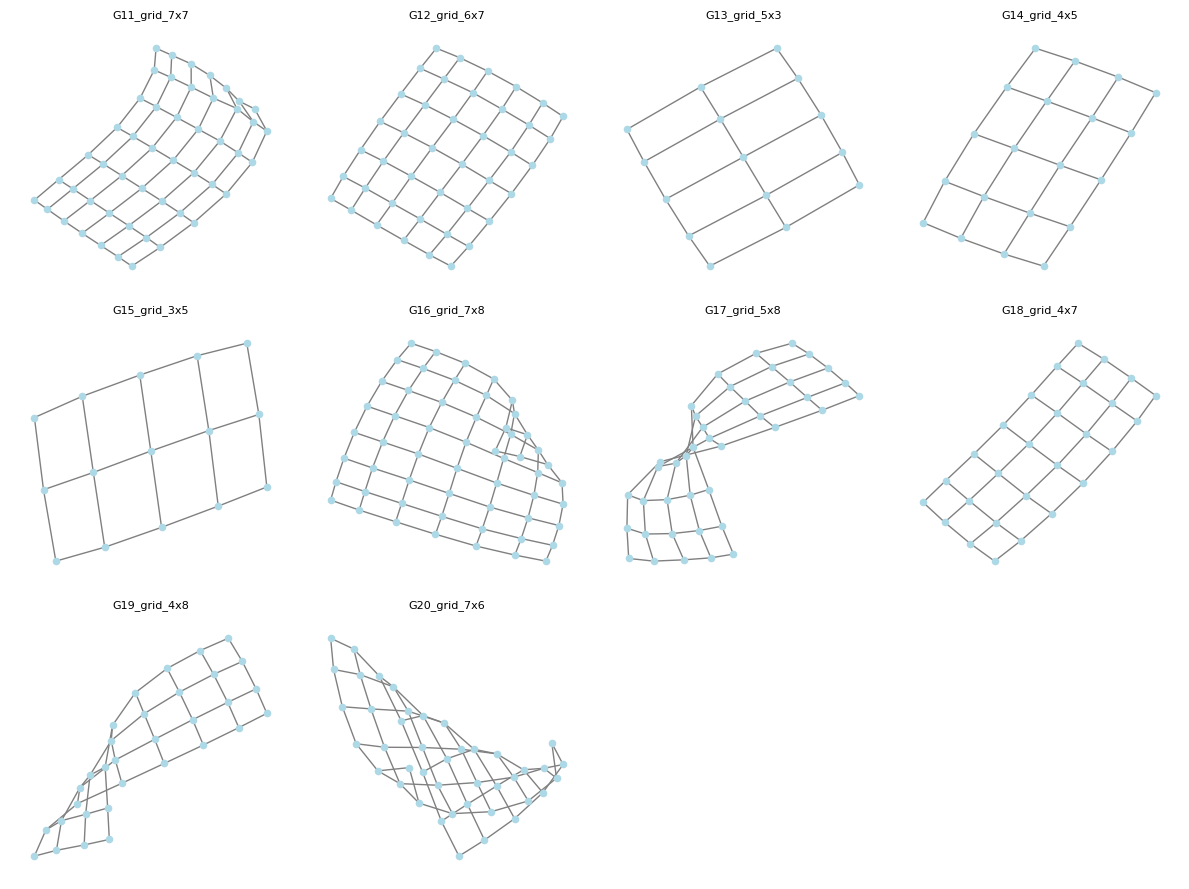

In [6]:
plot_weighted_graphs(graphs[10:20])

In [5]:
# 4) Compute every graph's Q matrix
Q_list = []

for graph in graphs:
    Q = compute_Q(graph)
    Q_list.append(Q)
    
names = [graph.graph.get("name", f"G{i + 1}") for i, graph in enumerate(graphs)]


In [6]:
from tqdm import tqdm

gamma = 0.01
n = len(Q_list)

kt_matrix = np.zeros((n, n), dtype=float)   # kt = ktte
ktw_matrix = np.zeros((n, n), dtype=float)  # ktw = kttw

for i in tqdm(range(n), desc="Computing kernel rows"):
    for j in range(n):
        #kt_matrix[i, j] = ktte(Q_list[i], Q_list[j], gamma=gamma)
        ktw_matrix[i, j] = kttw(Q_list[i], Q_list[j], gamma=gamma)



Computing kernel rows:   1%|          | 5/500 [00:13<23:05,  2.80s/it]


KeyboardInterrupt: 

In [7]:
from sklearn.svm import OneClassSVM

clf = OneClassSVM(kernel="precomputed", nu=0.1)

clf.fit(ktw_matrix)

OneClassSVM(kernel='precomputed', nu=0.1)

In [38]:
import osmnx as ox
import networkx as nx
import numpy as np
import random

ox.settings.use_cache = True
ox.settings.log_console = False


############################
# normalize edge weights
############################

def normalize_edge_lengths(G):

    lengths = [data.get("length", 1.0) for _,_,data in G.edges(data=True)]

    min_l = min(lengths)
    max_l = max(lengths)

    for u,v,data in G.edges(data=True):

        l = data.get("length",1.0)

        if max_l > min_l:
            w = (l-min_l)/(max_l-min_l)
        else:
            w = 0.5

        data["weight"] = float(w)

    return G


############################
# clean graph
############################

def clean_graph(G):

    G = ox.convert.to_undirected(G)

    G = nx.Graph(G)

    largest = max(nx.connected_components(G), key=len)

    G = G.subgraph(largest).copy()

    return G


############################
# crop graph size
############################

def crop_graph(G, max_nodes=20):

    if len(G.nodes()) <= max_nodes:
        return G

    start = random.choice(list(G.nodes()))

    nodes = list(nx.bfs_tree(G,start).nodes())[:max_nodes]

    return G.subgraph(nodes).copy()


############################
# download graph
############################

def get_graph(center):

    G = ox.graph_from_point(center, dist=300, network_type="drive")

    G = clean_graph(G)

    G = normalize_edge_lengths(G)

    G = crop_graph(G)

    return G


############################
# grid-like city centers
############################

grid_centers = [

    (40.7549, -73.9840),   # Manhattan
    (41.8827, -87.6268),   # Manhattan
    (45.5231, -122.6765),     # Barcelona Eixample
    (40.7608, -111.8910), # Phoenix
    (33.4484, -112.0740),  # Phoenix

]


############################
# non-grid cities
############################

non_grid_centers = [

    (38.7141, -9.1452),   # Rome
    (37.77501, -122.41934),
    (41.0335, 28.9770),   # Prague
    (31.6316, -7.9967),   # Lisbon
    (43.2569, -2.9236)
]

############################
# load graphs
############################

test_graphs = []

for center in grid_centers:

    G = get_graph(center)
    print('Getting_graph')
    test_graphs.append(("grid", center, G))


for center in non_grid_centers:

    G = get_graph(center)
    print('Getting_graph')

    test_graphs.append(("non_grid", center, G))


print("Loaded",len(test_graphs),"graphs")

Getting_graph
Getting_graph
Getting_graph
Getting_graph
Getting_graph
Getting_graph
Getting_graph
Getting_graph
Getting_graph
Getting_graph
Loaded 10 graphs


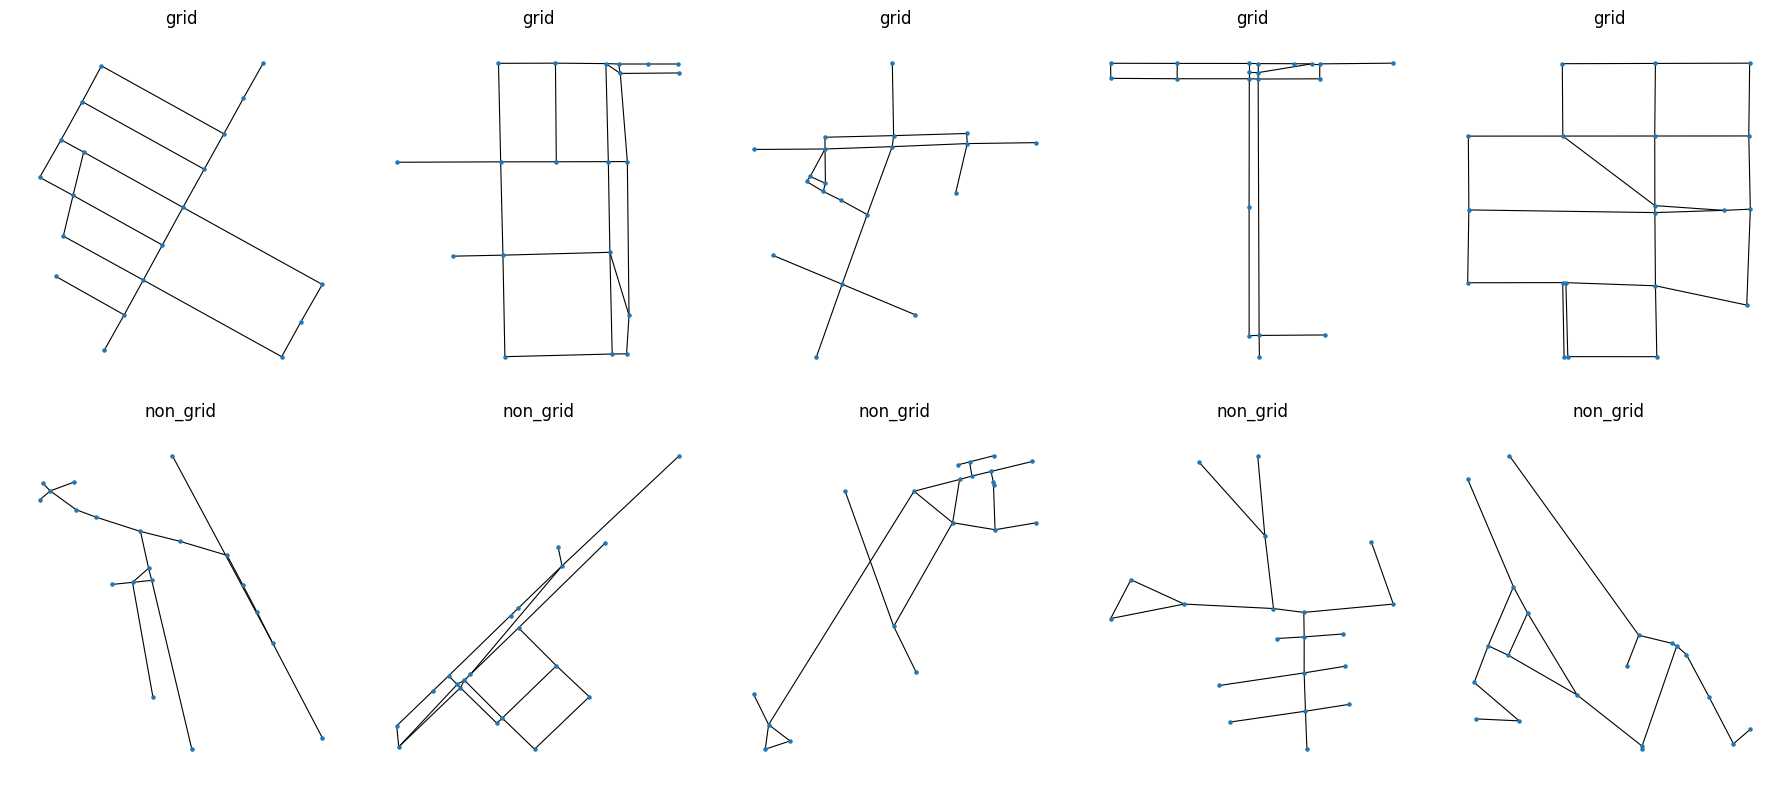

In [39]:
import matplotlib.pyplot as plt
import networkx as nx

fig, axes = plt.subplots(2, 5, figsize=(18,8))
axes = axes.flatten()

for i, (label, center, G) in enumerate(test_graphs):
    ax = axes[i]

    pos = {n: (G.nodes[n]["x"], G.nodes[n]["y"]) for n in G.nodes()}

    nx.draw(
        G,
        pos,
        node_size=5,
        width=0.8,
        ax=ax
    )

    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [40]:
Q_test = [compute_Q(G) for _,_,G in test_graphs]
k_test = np.zeros((len(Q_test), len(Q_list)))

for i in range(len(Q_test)):
    for j in range(len(Q_list)):
        k_test[i,j] = kttw(Q_test[i], Q_list[j], gamma=gamma)


pred = clf.predict(k_test)

In [11]:
for i in range(0,len(k_test)):
    print(k_test[i].max())

0.9671883647773879
0.9670957606830988
0.9792627610077612
0.9733842797758105
0.959440033348913
0.9794558875179791
0.9806981768722154
0.9913642333759353
0.9823651494773867
0.9877844828480622


In [41]:
pred

array([ 1,  1,  1,  1,  1, -1,  1, -1, -1, -1])